#### Libraries

In [1]:
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
from scipy.stats import norm

#### Parameters

In [2]:
alpha = 0.95
k = norm.pdf(norm.ppf(alpha)) / (1 - alpha)
print(k) 

2.0627128075074257


#### Sets

In [3]:
df = pd.read_csv("selected_monthly_return.csv", encoding="utf-8-sig")
tickers = df["Ticker"].tolist()
returns = df.drop(columns=["PERMNO", "Ticker", "average_monthly_return"])
mu = df["average_monthly_return"].to_numpy(dtype=float)

#### Covariance Matrix

In [4]:
cov_df = pd.read_csv("covariance_matrix.csv", skiprows=1, encoding="utf-8-sig")

Sigma = cov_df.drop(columns=["PERMNO", "Ticker"]).to_numpy(dtype=float)

eigvals, eigvecs = np.linalg.eigh(Sigma)
A = np.sqrt(np.clip(eigvals, 0, None))[:, None] * eigvecs.T

In [5]:
# Identify stock pairs with correlation above 0.8

rho_threshold = 0.80

std = np.sqrt(np.diag(Sigma))
corr_matrix = Sigma / np.outer(std, std)

conflicting_pairs = []

for i in range(len(tickers)):
    for j in range(i + 1, len(tickers)):
        if corr_matrix[i, j] > rho_threshold:
            conflicting_pairs.append((i, j))

print("Number of conflicting pairs:", len(conflicting_pairs))

for i, j in conflicting_pairs:
    print(tickers[i], tickers[j],
          f"Correlation: {corr_matrix[i, j]:.4f}")

Number of conflicting pairs: 8
NEM B Correlation: 0.8273
NEM AEM Correlation: 0.8058
KLAC LRCX Correlation: 0.8477
LRCX MU Correlation: 0.8206
B AEM Correlation: 0.8006
B WPM Correlation: 0.8137
AEM KGC Correlation: 0.8361
AEM WPM Correlation: 0.8486


### Model

$$
\begin{aligned}
\min_{w,z}\quad
&-\sum_{i\in I}\hat{\mu}_i^M w_i
+k_\alpha\|Aw\|_2 \\[6pt]
\text{s.t.}\quad
&\sum_{i\in I}w_i=1,\\[4pt]
&0.01z_i\leq w_i\leq0.20z_i,
&&\forall i\in I,\\[4pt]
&z_i+z_j\leq1,
&&\forall(i,j)\in P,\\[4pt]
&\sum_{i\in I}\hat{\mu}_i^M w_i\geq b,\\[4pt]
&z_i\in\{0,1\},
&&\forall i\in I.
\end{aligned}
$$

In [6]:
# model
m = gp.Model("portfolio")

Set parameter Username
Set parameter LicenseID to value 2871508
Academic license - for non-commercial use only - expires 2027-10-05


#### Decision Variables

In [7]:
# weights
w = m.addMVar(len(tickers), vtype=GRB.CONTINUOUS, name="w")
# indicator variable for investing in a specific stock
z = m.addMVar(len(tickers), vtype=GRB.BINARY, name="z")
# standard deviation of portfolio (helper variable)
s = m.addVar(vtype=GRB.CONTINUOUS, name="s")

#### Constraints

In [8]:
# full investment of capital
m.addConstr(w.sum() == 1, name="full_investment")
# min and max weight
m.addConstr(w <= 0.2 * z, name="max_investment")
m.addConstr(0.01 * z <= w, name = "min_investment")
# correlation restriction
for i, j in conflicting_pairs:
    m.addConstr(
        z[i] + z[j] <= 1,
        name=f"correlation_{i}_{j}"
    )

In [9]:
# average returns at least as good as s&p
benchmark = pd.read_csv("SP500_monthly_202001_202603.csv", encoding="utf-8-sig")
benchmark["Month"] = pd.to_datetime(benchmark["Month"])
b = benchmark.loc[benchmark["Month"].between("2021-01-01", "2025-12-31"), "MonthlyReturn"].mean()
m.addConstr(w @ mu >= b, name="minimum_return")

<MConstr () *awaiting model update*>

In [10]:
# helper constraint for the standard deviation to be added to objective function
y = m.addMVar(len(tickers), lb=-GRB.INFINITY, name="y") # helper variable for finding s 
m.addConstr(y == A @ w)
m.addGenConstrNorm(s, y, 2.0) # constraint to find s

<gurobi.GenConstr *Awaiting Model Update*>

#### Objective Function

In [11]:
m.setObjective(-1 * w @ mu + k * s, gp.GRB.MINIMIZE)

#### Results

In [12]:
m.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 9 185H, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 22 logical processors, using up to 22 threads

Optimize a model with 121 rows, 112 columns and 1644 nonzeros (Min)
Model fingerprint: 0x3b893291
Model has 38 linear objective coefficients
Model has 1 simple general constraint
  1 NORM
Variable types: 75 continuous, 37 integer (37 binary)
Coefficient statistics:
  Matrix range     [1e-06, 1e+00]
  Objective range  [2e-03, 2e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e-02, 1e+00]

Presolve removed 3 rows and 0 columns
Presolve time: 0.01s
Presolved: 119 rows, 149 columns, 1672 nonzeros
Presolved model has 37 quadratic constraint(s)
Variable types: 112 continuous, 37 integer (37 binary)

Root relaxation: objective -3.969804e-02, 43 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds   

In [13]:
portfolio = pd.DataFrame({"Ticker": tickers, "Optimized Weight": w.X})
print(portfolio.to_string(index=False, formatters={"Optimized Weight": "{:.3%}".format}))

Ticker Optimized Weight
  COHR           0.000%
    GE           0.000%
   FNV           0.000%
    UI           0.000%
  BABA           3.801%
  LITE           0.000%
  CVNA           0.000%
   CVS           6.812%
   NET           0.000%
  PLTR           0.000%
  SOFI           0.000%
   NEM           0.000%
   CAH          19.981%
   GLW           0.000%
   HWM           0.000%
  KLAC           0.000%
  LRCX           0.000%
    MU           0.000%
  INTC           0.000%
   AMD           0.000%
   WDC           0.000%
     B           0.000%
  IDXX           0.000%
   AEM           0.000%
  ESLT          20.000%
  CIEN           0.000%
   APH           0.000%
   FIX           7.819%
    MT           0.000%
   CLS           0.000%
  INSM           4.157%
    DB           8.114%
   STX           0.000%
   KGC           0.000%
   NRG           0.000%
   WPM          14.054%
  AVGO          15.262%


In [14]:
portfolio_return = mu @ w.X

print(f"Portfolio returns: {portfolio_return:.6%}")
print(f"Portfolio monthly standard deviation: {s.X:.6%}")
print(f"Portfolio monthly 95% CVaR: {m.ObjVal:.6%}")

Portfolio returns: 3.004309%
Portfolio monthly standard deviation: 4.331404%
Portfolio monthly 95% CVaR: 5.930133%


In [15]:
print(f"Historical benchmark mean monthly return b: {b:.6%}") # 2021-2025
print(f"Excess return: {(portfolio_return - b):.6%}")

Historical benchmark mean monthly return b: 1.099027%
Excess return: 1.905282%


### Actual Portfolio Return vs. Actual S&P 500 Return in Jan 2026

In [16]:
# Out-of-sample evaluation: January 2026
sp500_jan = benchmark.loc[
    benchmark["Month"].dt.to_period("M") == "2026-01",
    "MonthlyReturn"
].iloc[0]

actual_jan_return = df["26-Jan"].to_numpy(dtype=float) @ w.X

actual_excess_return = actual_jan_return - sp500_jan

print(f"Actual portfolio return in January 2026: {actual_jan_return:.6%}")
print(f"Actual S&P 500 return in January 2026: {sp500_jan:.6%}")
print(f"Actual excess return in January 2026: {actual_excess_return:.6%}")

Actual portfolio return in January 2026: 8.060061%
Actual S&P 500 return in January 2026: 1.366446%
Actual excess return in January 2026: 6.693616%


### Out-of-Sample Evaluation: January–March 2026

In [18]:
# Buy-and-hold portfolio without rebalancing

months = ["2026-01", "2026-02", "2026-03"]
stock_cols = ["26-Jan", "26-Feb", "26-Mar"]

# Actual monthly returns of the 37 stocks
stock_returns = df[stock_cols].to_numpy(dtype=float)

# Optimized portfolio weights determined at Dec 2025
initial_weights = np.array(w.X, dtype=float)
initial_weights = initial_weights / initial_weights.sum()

# Actual S&P 500 monthly returns
sp500_returns = (
    benchmark.set_index(benchmark["Month"].dt.strftime("%Y-%m"))
    .loc[months, "MonthlyReturn"]
    .to_numpy(dtype=float)
)

# Value of each stock position over time
position_values = initial_weights.copy()
portfolio_monthly_returns = []
portfolio_cumulative_returns = []

for t in range(len(months)):
    previous_total = position_values.sum()

    # Apply realized monthly stock returns
    position_values *= (1 + stock_returns[:, t])

    current_total = position_values.sum()

    monthly_return = current_total / previous_total - 1

    portfolio_monthly_returns.append(monthly_return)
    portfolio_cumulative_returns.append(current_total - 1)

# S&P 500 cumulative returns
sp500_cumulative_returns = (
    np.cumprod(1 + sp500_returns) - 1
)

# Summary table
comparison = pd.DataFrame({
    "Month": months,
    "Portfolio Monthly Return": portfolio_monthly_returns,
    "S&P 500 Monthly Return": sp500_returns,
    "Portfolio Cumulative Return": portfolio_cumulative_returns,
    "S&P 500 Cumulative Return": sp500_cumulative_returns
})

print(comparison.to_string(
    index=False,
    formatters={
        col: "{:.4%}".format
        for col in comparison.columns if col != "Month"
    }
))

print("\nThree-month cumulative results:")
print(f"Portfolio: {portfolio_cumulative_returns[-1]:.4%}")
print(f"S&P 500: {sp500_cumulative_returns[-1]:.4%}")
print(
    f"Excess cumulative return: "
    f"{portfolio_cumulative_returns[-1] - sp500_cumulative_returns[-1]:.4%}"
)

  Month Portfolio Monthly Return S&P 500 Monthly Return Portfolio Cumulative Return S&P 500 Cumulative Return
2026-01                  8.0601%                1.3664%                     8.0601%                   1.3664%
2026-02                  7.6020%               -0.8669%                    16.2748%                   0.4877%
2026-03                 -4.9171%               -5.0936%                    10.5575%                  -4.6307%

Three-month cumulative results:
Portfolio: 10.5575%
S&P 500: -4.6307%
Excess cumulative return: 15.1882%


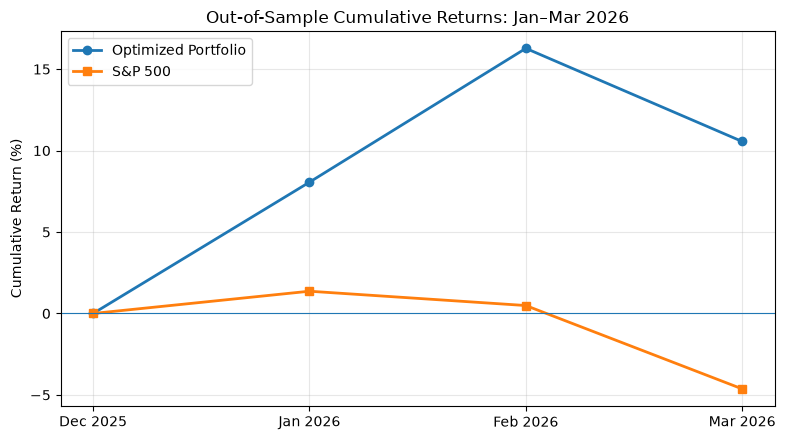

In [19]:
import matplotlib.pyplot as plt

# Include initial portfolio value at Dec 2025
plot_months = ["Dec 2025", "Jan 2026", "Feb 2026", "Mar 2026"]

portfolio_cum = [0] + portfolio_cumulative_returns
sp500_cum = [0] + sp500_cumulative_returns.tolist()

plt.figure(figsize=(8, 4.5))

plt.plot(
    plot_months,
    np.array(portfolio_cum) * 100,
    marker="o",
    linewidth=2,
    label="Optimized Portfolio"
)

plt.plot(
    plot_months,
    np.array(sp500_cum) * 100,
    marker="s",
    linewidth=2,
    label="S&P 500"
)

plt.axhline(0, linewidth=0.8)
plt.ylabel("Cumulative Return (%)")
plt.title("Out-of-Sample Cumulative Returns: Jan–Mar 2026")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure for Overleaf
plt.savefig("performance_comparison.png", dpi=300)
plt.show()

### Sanity Checks

In [17]:
# Verify the optimized portfolio independently
weights = np.array(w.X)
selected = np.array(z.X)
tol = 1e-5

# 1. Full investment
print("Sum of weights:", weights.sum())
print("Full investment:",
      abs(weights.sum() - 1) <= tol)

# 2. Minimum and maximum stock weights
print("Minimum investment:",
      np.all(weights >= 0.01 * selected - tol))
print("Maximum investment:",
      np.all(weights <= 0.20 * selected + tol))

# 3. Minimum expected return
expected_return = mu @ weights
print("Return requirement:",
      expected_return >= b - tol)

# 4. Correlation restriction
violations = [
    (tickers[i], tickers[j])
    for i, j in conflicting_pairs
    if selected[i] + selected[j] > 1 + tol
]

print("Correlation violations:", violations)

# 5. Independently calculate standard deviation and CVaR
calculated_std = np.linalg.norm(A @ weights)
calculated_cvar = -expected_return + k * calculated_std

print(f"Calculated standard deviation: {calculated_std:.6%}")
print(f"Calculated CVaR: {calculated_cvar:.6%}")
print(f"Gurobi CVaR: {m.ObjVal:.6%}")
print(f"CVaR difference: {abs(calculated_cvar - m.ObjVal):.10f}")
print(f"Maximum constraint violation: {m.ConstrVio:.10f}")

Sum of weights: 1.000000058077926
Full investment: True
Minimum investment: True
Maximum investment: True
Return requirement: True
Correlation violations: []
Calculated standard deviation: 4.331404%
Calculated CVaR: 5.930134%
Gurobi CVaR: 5.930133%
CVaR difference: 0.0000000050
Maximum constraint violation: 0.0000000581
